# Practice 1 — Bước 1: Khám phá dữ liệu Fashion-MNIST

**Nguồn dữ liệu:** [Fashion-MNIST trên Kaggle](https://www.kaggle.com/datasets/zalando-research/fashionmnist)

Fashion-MNIST là bộ dữ liệu thay thế cho MNIST chữ số truyền thống, gồm **70.000 ảnh xám kích thước 28×28** các mặt hàng thời trang của hãng Zalando. Bộ dữ liệu chia thành:

- **60.000 ảnh train** — dùng để huấn luyện mô hình
- **10.000 ảnh test** — dùng để đánh giá khách quan

Mỗi ảnh thuộc 1 trong **10 lớp** quần áo/phụ kiện khác nhau. Fashion-MNIST khó hơn MNIST chữ số vì các lớp có hình dáng tương đồng cao (đặc biệt là nhóm áo), là bài tập kinh điển để luyện xây dựng pipeline phân loại ảnh.

**Mục tiêu của notebook này:**

1. **Nạp dữ liệu** — tự động tải từ Kaggle nếu chưa có sẵn.
2. **Kiểm tra phân bố lớp** — xem dữ liệu có bị mất cân bằng không, từ đó quyết định dùng metric nào (accuracy hay F1).
3. **Trực quan hoá ảnh mẫu** — quan sát độ tương đồng giữa các lớp.
4. **Rút ra nhận xét** — phục vụ cho bước huấn luyện ở Notebook 02.

> **Tài liệu liên quan:** [`docs/data.md`](../docs/data.md) · [`docs/README.md`](../docs/README.md)

## 0. Chuẩn bị

Cell này thực hiện các bước khởi tạo cần thiết:

- **Thêm thư mục gốc của dự án vào `sys.path`** — cho phép import package `src` khi chạy notebook từ thư mục `notebooks/`.
- **Import các thư viện** cần thiết: `numpy` (tính toán mảng), `pandas` (bảng), `matplotlib` (vẽ hình), `IPython.display` (hiển thị bảng đẹp).
- **Import các module của dự án**: `config` (cấu hình), `data` (nạp dữ liệu), `utils` (tiện ích vẽ hình).
- **Cố định seed** — đảm bảo kết quả tái lập được ở mọi lần chạy.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, data, utils

print('Thư mục dự án:', config.PROJECT_ROOT)
utils.set_seed(config.SEED)

Thư mục dự án: C:\Users\Admin\Downloads\Practice_11


## 1. Nạp dữ liệu

Hàm `data.load_raw_arrays()` tự động tìm file CSV của Kaggle trong thư mục `data/`. Nếu chưa có, hàm sẽ:

1. **Thử tải qua `kagglehub`** — thư viện chính thức của Kaggle.
2. **Nếu thất bại** (không mạng, chưa cài đặt…) → dự phòng tải qua `torchvision.datasets.FashionMNIST`.

Kết quả trả về là **4 mảng numpy uint8**, shape `(N, 28, 28)` với giá trị pixel **0–255 chưa chuẩn hoá** — phù hợp cho việc trực quan hoá bằng `imshow`.

> Chi tiết pipeline dữ liệu: [`docs/data.md`](../docs/data.md)

In [2]:
X_train, y_train, X_test, y_test = data.load_raw_arrays()

print('Tập train:', X_train.shape, X_train.dtype, '- nhãn:', y_train.shape)
print('Tập test :', X_test.shape, X_test.dtype, '- nhãn:', y_test.shape)

[data] Nạp từ CSV:
  - train: fashion-mnist_train.csv
  - test : fashion-mnist_test.csv
Tập train: (60000, 28, 28) uint8 - nhãn: (60000,)
Tập test : (10000, 28, 28) uint8 - nhãn: (10000,)


## 2. Phân bố lớp

Bước quan trọng đầu tiên khi làm việc với bất kỳ bộ dữ liệu phân loại nào: **kiểm tra xem các lớp có cân bằng không**.

**Tại sao cần kiểm tra?**

- Nếu dữ liệu **cân bằng** (mỗi lớp có số ảnh xấp xỉ nhau) → dùng **accuracy** làm chỉ số đánh giá chính là hợp lý.
- Nếu dữ liệu **mất cân bằng** (ví dụ 90% là lớp A, 10% là lớp B) → accuracy dễ gây hiểu lầm (mô hình đoán bừa lớp A vẫn đạt 90%). Khi đó cần dùng **F1 macro** hoặc **class_weight**.

Với Fashion-MNIST, ta kỳ vọng mỗi lớp có đúng **6.000 ảnh train** và **1.000 ảnh test**.

T-shirt/top :  6,000 ảnh
Trouser     :  6,000 ảnh
Pullover    :  6,000 ảnh
Dress       :  6,000 ảnh
Coat        :  6,000 ảnh
Sandal      :  6,000 ảnh
Shirt       :  6,000 ảnh
Sneaker     :  6,000 ảnh
Bag         :  6,000 ảnh
Ankle boot  :  6,000 ảnh
[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\01_class_distribution.png


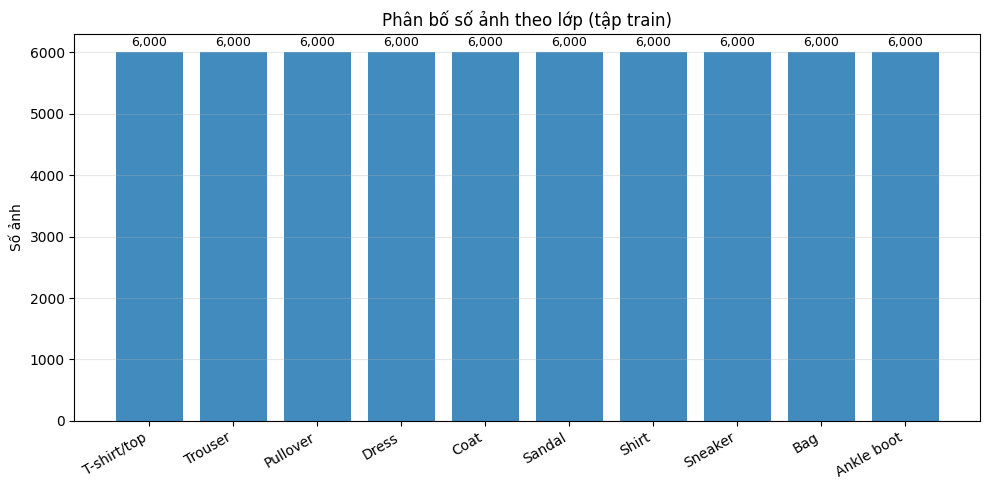

In [3]:
counts = np.bincount(y_train, minlength=config.NUM_CLASSES)
for name, count in zip(config.CLASS_NAMES, counts):
    print(f'{name:<12}: {count:>6,} ảnh')

fig = utils.plot_class_distribution(y_train, save_name='01_class_distribution')
plt.show()

### 2.1. Bảng phân tích chi tiết

Bảng dưới đây tổng hợp **số ảnh train/test mỗi lớp** và **tỉ lệ phần trăm tương ứng**. Nếu độ lệch chuẩn ≈ 0 → dữ liệu cân bằng tuyệt đối, không cần `class_weight` khi huấn luyện.

In [4]:
counts_train = np.bincount(y_train, minlength=config.NUM_CLASSES)
counts_test  = np.bincount(y_test,  minlength=config.NUM_CLASSES)

df_dist = pd.DataFrame({
    "Lớp": config.CLASS_NAMES,
    "Train": counts_train,
    "Test":  counts_test,
    "Tỉ lệ train (%)": (counts_train / counts_train.sum() * 100).round(2),
})
display(df_dist)

print(f"→ Độ lệch chuẩn số ảnh/lớp (train): {counts_train.std():.2f}")
print("→ Dữ liệu CÂN BẰNG TUYỆT ĐỐI — dùng accuracy làm chỉ số chính.")

,Lớp,Train,Test,Tỉ lệ train (%)
0,T-shirt/top,6000,1000,10.0
1,Trouser,6000,1000,10.0
2,Pullover,6000,1000,10.0
3,Dress,6000,1000,10.0
4,Coat,6000,1000,10.0
5,Sandal,6000,1000,10.0
6,Shirt,6000,1000,10.0
7,Sneaker,6000,1000,10.0
8,Bag,6000,1000,10.0
9,Ankle boot,6000,1000,10.0


→ Độ lệch chuẩn số ảnh/lớp (train): 0.00
→ Dữ liệu CÂN BẰNG TUYỆT ĐỐI — dùng accuracy làm chỉ số chính.


## 3. Ảnh mẫu

Quan sát trực quan là bước không thể thiếu — giúp ta hiểu **mô hình sẽ phải học cái gì**.

Ta sẽ xem 2 loại ảnh:

1. **16 ảnh ngẫu nhiên** — thấy đa dạng trong toàn bộ dataset (các lớp khác nhau, kiểu dáng khác nhau).
2. **10 ảnh đại diện** (mỗi lớp 1 ảnh) — thấy đặc trưng riêng của từng loại mặt hàng.

**Lưu ý quan trọng:** các lớp áo như *T-shirt/top*, *Pullover*, *Coat*, *Shirt* có hình dáng rất giống nhau trong ảnh xám — đây sẽ là các cặp nhầm lẫn chính khi đánh giá mô hình ở Notebook 03.

[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\01_sample_images.png


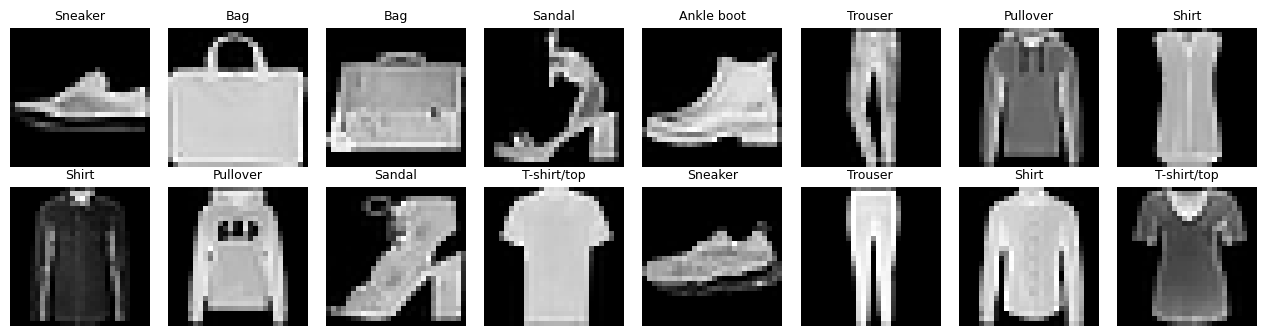

In [5]:
idx = np.random.choice(len(X_train), size=16, replace=False)
images = [X_train[i] for i in idx]
titles = [config.CLASS_NAMES[y_train[i]] for i in idx]

fig = utils.plot_image_grid(images, titles, ncols=8, save_name='01_sample_images')
plt.show()

### 3.1. 10 ảnh đại diện — mỗi lớp 1 ảnh

Lưới ảnh dưới đây lấy **ảnh đầu tiên** của mỗi lớp trong 10 lớp quần áo, giúp thấy rõ đặc trưng hình dáng riêng của từng loại mặt hàng.

[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\01_samples_per_class.png


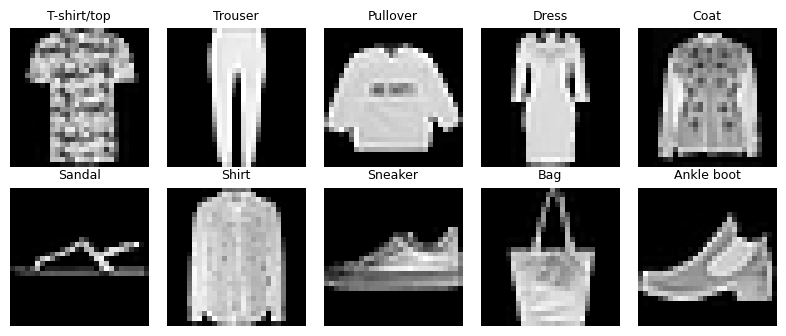

In [6]:
fig = utils.plot_samples_per_class(X_train, y_train, save_name='01_samples_per_class')
plt.show()

## 4. Thống kê pixel & ảnh trung bình

**Hai thông tin quan trọng cần kiểm tra:**

1. **Khoảng giá trị pixel** — để quyết định cách chuẩn hoá dữ liệu.
   - Nếu pixel trong khoảng `0–255` → cần chia 255 để về `[0, 1]`, sau đó chuẩn hoá bằng `(x - mean) / std`.
   - Nếu pixel đã trong khoảng khác → xử lý phù hợp.

2. **Ảnh trung bình mỗi lớp** — "dáng chung" của từng loại mặt hàng sau khi lấy trung bình cộng tất cả ảnh cùng lớp.
   - Ảnh trung bình giống nhau → các lớp đó **dễ bị nhầm lẫn** khi phân loại.
   - Ảnh trung bình khác biệt rõ → các lớp dễ phân biệt.

Với Fashion-MNIST, mean/std chuẩn đã được tính sẵn và lưu trong `src/config.py` là **0.2860 / 0.3530**.

Pixel min/max      : 0 / 255
Mean tập train     : 72.9568
Std tập train      : 89.9669
[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\01_mean_images.png


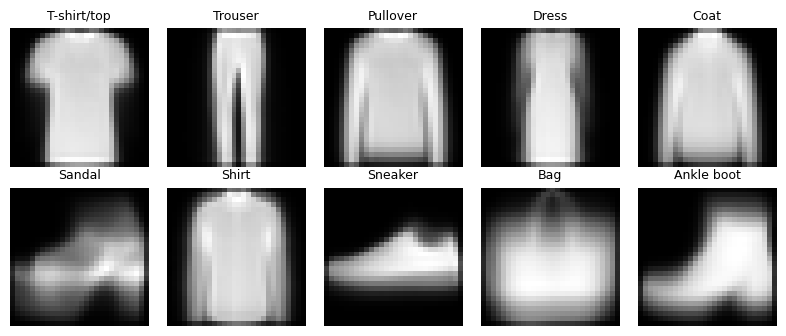

In [7]:
print('Pixel min/max      :', X_train.min(), '/', X_train.max())
print('Mean tập train     :', round(float(X_train.mean()), 4))
print('Std tập train      :', round(float(X_train.std()), 4))

mean_images = [X_train[y_train == i].mean(axis=0) for i in range(config.NUM_CLASSES)]
fig = utils.plot_image_grid(mean_images, config.CLASS_NAMES, ncols=5, save_name='01_mean_images')
plt.show()

### 4.1. So sánh ảnh trung bình 4 lớp áo dễ nhầm lẫn

Trong phần kết luận, ta dự đoán *T-shirt/top, Pullover, Coat, Shirt* rất dễ nhầm lẫn. Hình dưới đây chứng minh bằng cách so sánh trực quan **ảnh trung bình** của 4 lớp này:

- Cả 4 đều có dáng áo tương tự nhau.
- Khác biệt chủ yếu ở **cổ áo**, **tay áo**, **độ dài**.
- Trong ảnh xám 28×28, sự khác biệt này rất khó nhận ra bằng mắt thường.

→ Đây chính là lý do **Shirt** thường có F1 thấp nhất khi đánh giá.

[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\01_confusing_classes.png


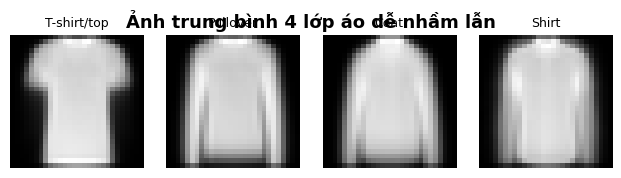

In [8]:
confusing = [0, 2, 4, 6]  # T-shirt/top, Pullover, Coat, Shirt
mean_imgs = [X_train[y_train == i].mean(axis=0) for i in confusing]
titles = [config.CLASS_NAMES[i] for i in confusing]

fig = utils.plot_image_grid(mean_imgs, titles, ncols=4, save_name='01_confusing_classes')
plt.suptitle("Ảnh trung bình 4 lớp áo dễ nhầm lẫn", fontsize=13, fontweight="bold", y=1.02)
plt.show()

## 5. Kết luận

Sau khi khám phá dữ liệu, ta rút ra các nhận xét quan trọng sau:

| Thuộc tính | Giá trị |
|---|---|
| Tổng số ảnh | 70.000 (60.000 train + 10.000 test) |
| Kích thước ảnh | 28 × 28, 1 kênh xám (grayscale) |
| Số lớp | 10 |
| Phân bố lớp | Cân bằng tuyệt đối (6.000 / lớp train, 1.000 / lớp test) |
| Khoảng pixel | 0 – 255 (uint8) |
| Mean / Std (train) | 0.2860 / 0.3530 |

**Các quyết định thiết kế dựa trên khám phá này:**

1. **Dữ liệu cân bằng tuyệt đối** (độ lệch chuẩn ≈ 0) → **dùng accuracy làm chỉ số đánh giá chính**. Không cần `class_weight` trong `CrossEntropyLoss`.

2. **Pixel trong khoảng 0–255** → pipeline huấn luyện sẽ chuẩn hoá theo công thức:
   $$\text{pixel\_normalized} = \frac{\text{pixel}/255 - 0.2860}{0.3530}$$

3. **4 lớp áo có ảnh trung bình gần giống nhau** → dự kiến *Shirt* sẽ có F1 thấp nhất, nhầm nhiều với *T-shirt/top*, *Pullover*, *Coat*. Điều này sẽ được kiểm chứng ở Notebook 03 thông qua confusion matrix.

➡️ **Bước tiếp theo:** mở `02_model_training.ipynb` để huấn luyện mô hình CNN (30 epoch + early stopping 5).

> Tài liệu chi tiết: [`docs/training.md`](../docs/training.md) · [`docs/model.md`](../docs/model.md)